# 从一次计算到工具执行

第一课教师演示 · 中文 · 2026-11-04

先“运行全部”，再修改半径重跑。前半段真实执行计算和绘图；后半段用**教师预写的请求模拟模型输出**，没有联网调用大模型。学生不需要自行编写这些程序。

教师准备见同目录 README.md。依赖 Python 3、Jupyter/IPython 和 matplotlib。

## 1. 算一个圆的面积

半径单位为 mm，面积单位为 mm²。先预测半径从 2 增大到 3 后面积如何变化。


In [1]:
import math

radius_mm = 2.0
area_mm2 = math.pi * radius_mm ** 2
print(f"半径：{radius_mm:g} mm；面积：{area_mm2:.2f} mm²")


半径：2 mm；面积：12.57 mm²


## 2. 一键画出半径与面积的关系

横轴为半径（mm），纵轴为面积（mm²）。圆点对应上一格的半径。修改上一格的半径后，再依次运行两格。

曲线是几何公式的结果，不是实验测量数据。图中使用英文标签，便于在未安装中文字体的电脑上显示。


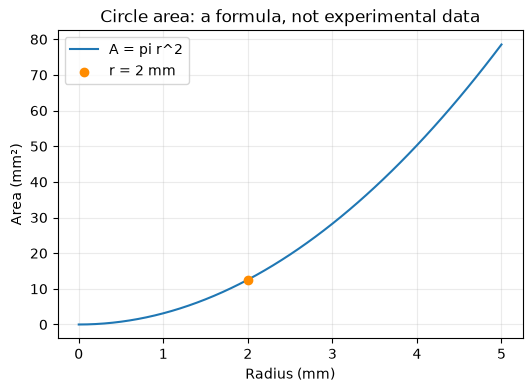

In [2]:
import matplotlib.pyplot as plt

radii_mm = [i / 10 for i in range(51)]
areas_mm2 = [math.pi * r ** 2 for r in radii_mm]
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(radii_mm, areas_mm2, label="A = pi r^2")
ax.scatter([radius_mm], [area_mm2], color="darkorange", zorder=3,
           label=f"r = {radius_mm:g} mm")
ax.set(xlabel="Radius (mm)", ylabel="Area (mm²)",
       title="Circle area: a formula, not experimental data")
ax.grid(alpha=0.25)
ax.legend()
plt.show()


## 3. 先准备一个可被调用的工具

`circle_area` 是工具名，`radius_mm` 是参数名。下面的代码负责实际计算，也检查参数是不是有限的非负数。这不是模型自己创造出来的工具，而是教师预先注册的函数。


In [3]:
def circle_area(radius_mm):
    if isinstance(radius_mm, bool) or not isinstance(radius_mm, (int, float)):
        raise ValueError("半径必须是数值")
    if not math.isfinite(radius_mm) or radius_mm < 0:
        raise ValueError("半径必须是有限的非负数")
    return {"area_mm2": math.pi * radius_mm ** 2}

print("可用工具：circle_area；参数：radius_mm，单位 mm")


可用工具：circle_area；参数：radius_mm，单位 mm


## 4. 模拟模型提出调用，再由外围程序执行

以下 JSON 是**教师预写的模拟请求**，不是某家 API 的完整报文。真实系统中，Harness 会把工具说明提供给模型，再按对应协议接收调用消息。

这里只允许执行已经登记的工具，不把任意文字直接当作代码运行。


In [4]:
import json

request_text = '{"name": "circle_area", "arguments": {"radius_mm": 2.0}}'

def dispatch(request_text):
    request = json.loads(request_text)
    if not isinstance(request, dict) or set(request) != {"name", "arguments"}:
        raise ValueError("请求需要 name 和 arguments")
    if request["name"] != "circle_area":
        raise ValueError("没有注册这个工具")
    arguments = request["arguments"]
    if not isinstance(arguments, dict) or set(arguments) != {"radius_mm"}:
        raise ValueError("参数需要 radius_mm")
    return circle_area(**arguments)

result = dispatch(request_text)
print("模拟请求：", request_text)
print("真实工具结果：", json.dumps(result, ensure_ascii=False))
print(f"教师预写的回答模板：面积约为 {result['area_mm2']:.2f} mm²。")


模拟请求： {"name": "circle_area", "arguments": {"radius_mm": 2.0}}
真实工具结果： {"area_mm2": 12.566370614359172}
教师预写的回答模板：面积约为 12.57 mm²。


## 5. 格式正确也不代表参数合理

下面的请求仍是有效 JSON，但半径为负数。观察调度程序与工具如何返回错误。真实系统可以把错误交回模型，让它补充信息或修改请求；本演示没有模拟自主重试。


In [5]:
bad_request = '{"name": "circle_area", "arguments": {"radius_mm": -2.0}}'
try:
    dispatch(bad_request)
except ValueError as error:
    print("工具拒绝请求：", error)


工具拒绝请求： 半径必须是有限的非负数


## 6. 对照与核验

- 直接计算和工具调用采用同一个圆面积公式。
- 半径 2 mm 的面积应为 4π mm²，约 12.57 mm²。
- 半径 3 mm 的面积是 9π mm²，约 28.27 mm²；它是前者的 2.25 倍。
- JSON 是请求的表达方式；实际运算发生在 `circle_area` 函数执行时。
- 计算输出与最后一句文字回答是不同步骤。

实际 Agent 还需要组织上下文、连接模型、管理执行权限及记录。这个小程序只演示其中的请求检查与工具分发。
